In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = r"Downloads/brain tumour/Training"
test = r"Downloads/brain tumour/Testing"

In [3]:
train_gen = ImageDataGenerator(rescale = 1./255).flow_from_directory(train,target_size = (224,224),batch_size = 32,class_mode = 'categorical')
test_gen = ImageDataGenerator(rescale = 1./255).flow_from_directory(test,target_size = (224,224),batch_size = 32,class_mode = 'categorical')

Found 2870 images belonging to 4 classes.
Found 394 images belonging to 4 classes.


In [4]:
class_names = list(train_gen.class_indices.keys())

print(class_names)

['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [5]:
model = Sequential([
    Conv2D(64,(3,3),activation = 'relu',input_shape = (224,224,3)),
    MaxPooling2D((2,2)),
    Conv2D(32,(3,3),activation = 'relu'),
    MaxPooling2D((2,2)),
    Conv2D(16,(3,3),activation = 'relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128,activation = 'relu'),
    Dense(4,activation = 'softmax')
    
])

C:\Users\sujal\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.compile(optimizer = 'adam',loss = 'categorical_crossentropy',metrics = ['accuracy'])

In [7]:
history = model.fit(train_gen,validation_data = test_gen,epochs = 5,verbose = 1)

Epoch 1/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 28s 288ms/step - accuracy: 0.6056 - loss: 0.9254 - val_accuracy: 0.4924 - val_loss: 1.7562
Epoch 2/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 23s 255ms/step - accuracy: 0.7972 - loss: 0.4947 - val_accuracy: 0.6218 - val_loss: 1.9410
Epoch 3/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 22s 243ms/step - accuracy: 0.8826 - loss: 0.3046 - val_accuracy: 0.6777 - val_loss: 2.0954
Epoch 4/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 21s 234ms/step - accuracy: 0.9359 - loss: 0.1697 - val_accuracy: 0.7183 - val_loss: 2.6087
Epoch 5/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 21s 237ms/step - accuracy: 0.9686 - loss: 0.0906 - val_accuracy: 0.7284 - val_loss: 3.8059


In [8]:
x_test,y_test = next(test_gen)
preds = np.argmax(model.predict(x_test[:5]),axis = 1)
actual = np.argmax(y_test[:5],axis = 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step


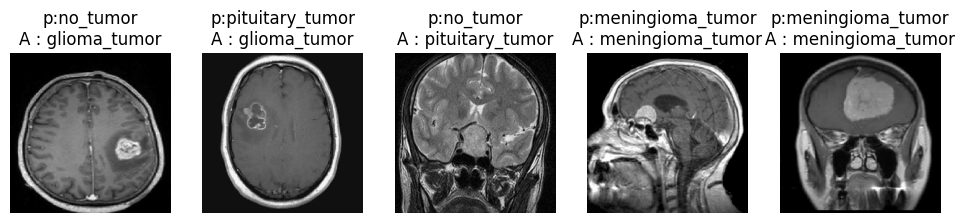

In [9]:
plt.figure(figsize = (12,4))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i])
    plt.title(f"p:{class_names[preds[i]]}\nA : {class_names[actual[i]]}")
    plt.axis('off')
plt.show()

In [10]:
print(history.history['accuracy'])
print(history.history['val_accuracy'])

[0.605574905872345, 0.797212541103363, 0.8825783729553223, 0.9358885288238525, 0.9686411023139954]
[0.49238577485084534, 0.6218274235725403, 0.6776649951934814, 0.7182741165161133, 0.7284263968467712]
